In [1]:
%pip install matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Matching curves: 615
Plotting: 5


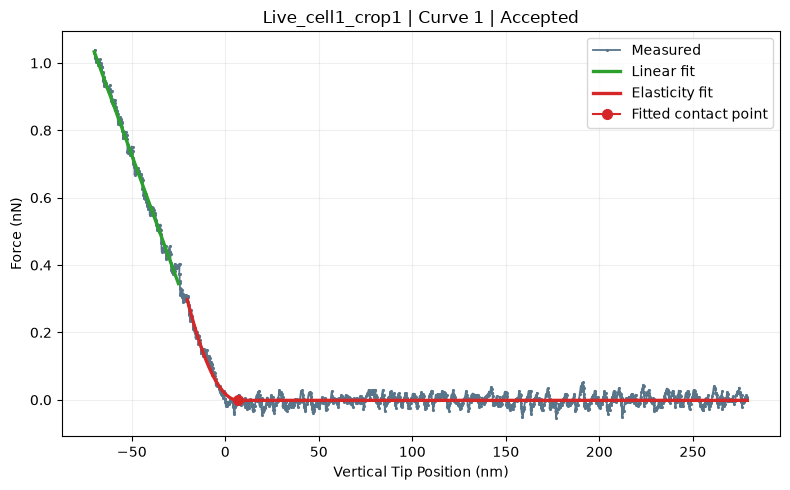

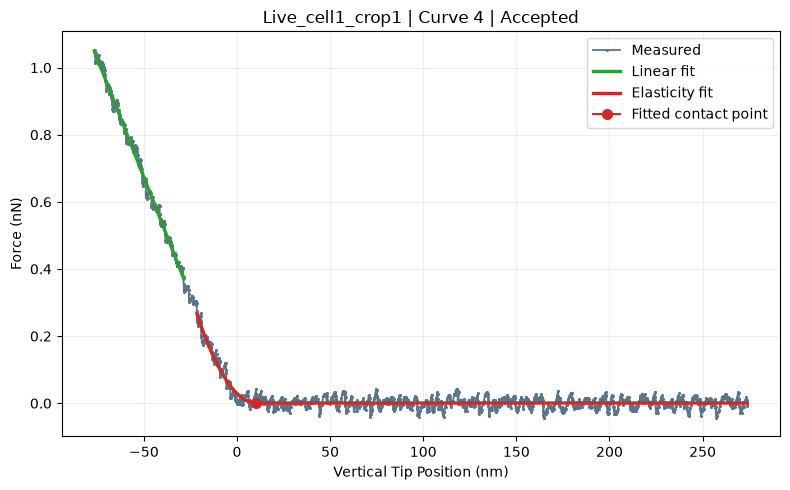

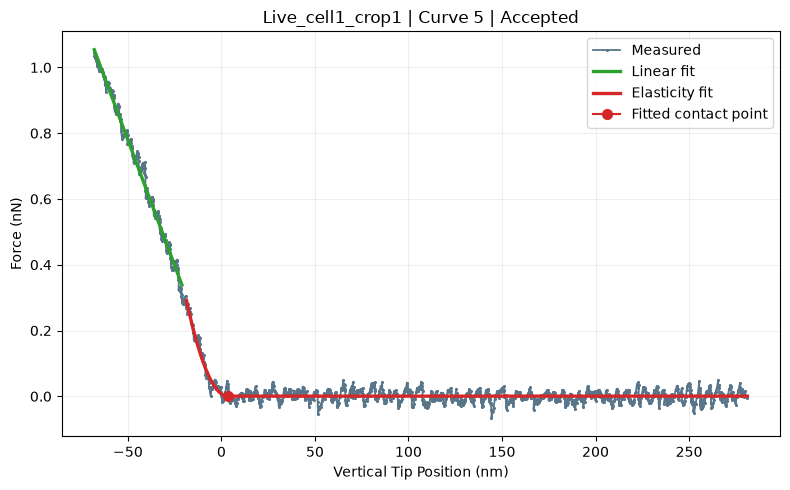

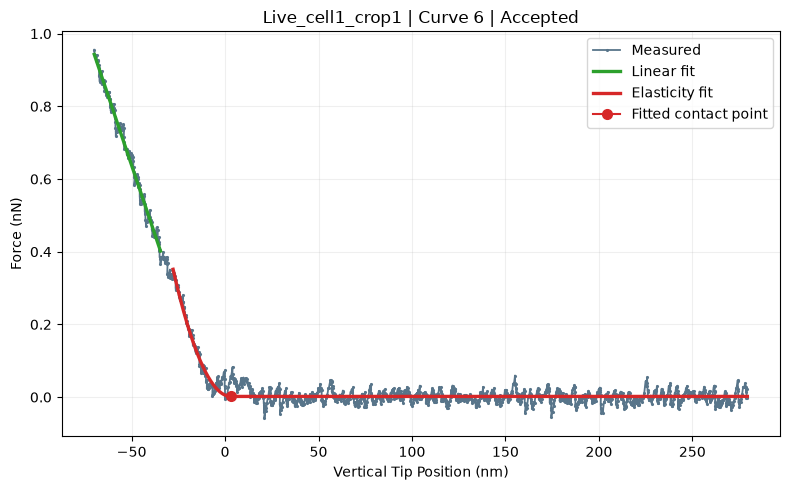

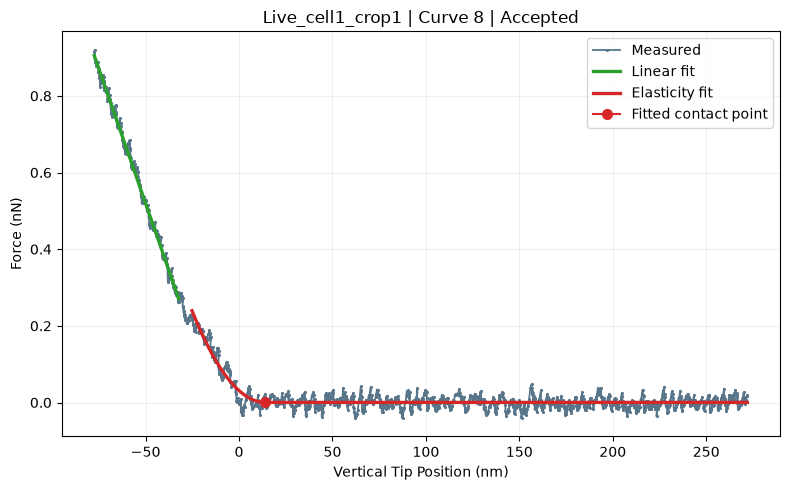

In [2]:
from pathlib import Path
import csv
import json
import math
import re
import statistics
from collections import defaultdict

# Shared definitions intentionally included inside each notebook.
# No external Python helper file is needed.
DATA_FOLDER = Path.cwd() / "csv_data"
CONDITIONS = ["Live", "20 mg/L", "320 mg/L", "Dead"]
LABELS = {"live": "Live", "20": "20 mg/L", "320": "320 mg/L", "dead": "Dead"}
FOLDER_RE = re.compile(r"^(Live|20|320|Dead)_cell(\d+)_crop(\d+)$", re.I)
LIMIT_RMS_PN = 25.0
MIN_LINEAR_NM = 5.0
MIN_ELASTICITY_NM = 10.0
MAX_OVERLAP_NM = 5.0


def read_csv(path):
    with path.open(encoding="utf-8-sig", newline="") as handle:
        return list(csv.DictReader(handle))


def num(value):
    try:
        result = float(value)
        return result if math.isfinite(result) else None
    except (ValueError, TypeError, OverflowError):
        return None


def identity(row):
    return (row.get("filename", ""), row.get("curve_number", ""),
            row.get("position_index", ""))


def interval(row, prefix):
    a = num(row.get(prefix + "_x_min_used_nm"))
    b = num(row.get(prefix + "_x_max_used_nm"))
    return tuple(sorted((a, b))) if a is not None and b is not None else None


def widths(row):
    linear = interval(row, "linear")
    elastic = interval(row, "elasticity")
    linear_nm = linear[1] - linear[0] if linear else None
    elasticity_nm = elastic[1] - elastic[0] if elastic else None
    # Indentation-side part of the fitted elasticity interval, relative to
    # the processed curve's contact at X = 0 nm, clipped to the fit interval.
    contact_nm = (max(0.0, min(0.0, elastic[1]) - elastic[0])
                  if elastic else None)
    overlap_nm = (max(0.0, min(linear[1], elastic[1]) - max(linear[0], elastic[0]))
                  if linear and elastic else None)
    xc = num(row.get("contact_point_x_nm"))
    fitted_contact_nm = (max(0.0, min(max(xc, elastic[0]), elastic[1]) - elastic[0])
                         if elastic and xc is not None else None)
    return linear_nm, elasticity_nm, contact_nm, fitted_contact_nm, overlap_nm


def trace(points, y_column, used_column=None):
    selected = []
    for row in points:
        if used_column and row.get(used_column) != "1":
            continue
        x, y = num(row.get("x_nm")), num(row.get(y_column))
        if x is not None and y is not None:
            selected.append([x, y])
    if used_column:
        selected.sort(key=lambda point: point[0])
    return selected


def elasticity_rms_from_points(points):
    """Recalculate custom RMS from actual plotted fitted points, in pN.

    Force values in the point CSV are nN, so multiply RMS by 1000.
    N is the number of valid pairs in the elasticity fitting interval.
    The three fitted parameters are E, contact position and baseline.
    """
    residual_sq = []
    for point in points:
        if point.get("elasticity_fit_used") != "1":
            continue
        measured = num(point.get("measured_y_nN"))
        predicted = num(point.get("elasticity_fit_y_nN"))
        if measured is not None and predicted is not None:
            residual_sq.append((measured - predicted) ** 2)
    n = len(residual_sq)
    if n <= 3:
        return None, n
    return math.sqrt(math.fsum(residual_sq) / (n - 3)) * 1000.0, n


def derived_values(summary, points):
    if summary is None:
        return {}
    v = dict(summary)
    slope = num(v.get("linear_slope_bruker_N_per_m"))
    linear_nm, elasticity_nm, contact_nm, fitted_nm, overlap_nm = widths(v)
    v["bacterial_spring_constant_nN_per_um"] = abs(slope) * 1000 if slope is not None else None
    v["linear_fit_range_nm"] = linear_nm
    v["elasticity_fit_range_nm"] = elasticity_nm
    v["elasticity_fit_range_to_preprocessing_contact_nm"] = contact_nm
    v["elasticity_fit_range_to_fitted_contact_nm"] = fitted_nm
    v["fit_overlap_nm"] = overlap_nm
    # Recompute directly instead of multiplying the old RMS a second time.
    # Correct for both old N and newer N-3 Jython exports, including 320 Cell 3.
    v["elasticity_rmsd_custom_pN"], v["elasticity_recalculated_T"] = elasticity_rms_from_points(points)
    jpk = num(v.get("elasticity_rms_bruker_pN"))
    custom = v["elasticity_rmsd_custom_pN"]
    v["elasticity_rms_difference_pN"] = (custom - jpk if custom is not None and jpk is not None else None)
    if custom is not None and jpk is not None:
        avg = (abs(custom) + abs(jpk)) / 2
        v["elasticity_rms_percentage_difference"] = abs(custom - jpk) / avg * 100 if avg else 0.0
    else:
        v["elasticity_rms_percentage_difference"] = None
    return v


def rejection_reasons(v):
    if not v:
        return ["No uniquely matching summary row"]
    checks = [
        (num(v.get("linear_rmsd_custom_pN")), "Linear RMS > 25 pN or missing", "max", LIMIT_RMS_PN),
        (num(v.get("elasticity_rms_bruker_pN")), "JPK elasticity RMS > 25 pN or missing", "max", LIMIT_RMS_PN),
        (v.get("linear_fit_range_nm"), "Linear fitting width < 5 nm or missing", "min", MIN_LINEAR_NM),
        (v.get("elasticity_fit_range_to_preprocessing_contact_nm"), "Elasticity indentation width < 10 nm or missing", "min", MIN_ELASTICITY_NM),
        (v.get("fit_overlap_nm"), "Fitting interval overlap > 5 nm or missing", "max", MAX_OVERLAP_NM),
    ]
    reasons = []
    for value, reason, direction, limit in checks:
        if value is None or (direction == "max" and value > limit) or (direction == "min" and value < limit):
            reasons.append(reason)
    return reasons


def curve_inventory():
    """Read point CSVs first, match summaries by full filename/curve/position.

    If historic curve_number in a point file is wrong, recover by a unique
    filename + position match. Summary-only leftovers are never included.
    """
    if not DATA_FOLDER.is_dir():
        raise FileNotFoundError("Run this notebook from the repository root containing csv_data")
    folders = [p for p in DATA_FOLDER.iterdir() if p.is_dir() and FOLDER_RE.fullmatch(p.name)]
    folders.sort(key=lambda p: (CONDITIONS.index(LABELS[FOLDER_RE.fullmatch(p.name).group(1).lower()]),
                                int(FOLDER_RE.fullmatch(p.name).group(2)),
                                int(FOLDER_RE.fullmatch(p.name).group(3))))
    for folder in folders:
        matcher = FOLDER_RE.fullmatch(folder.name)
        condition = LABELS[matcher.group(1).lower()]
        cell, crop = int(matcher.group(2)), int(matcher.group(3))
        paths = sorted(folder.glob("AFM_fit_points_curve_*.csv"))
        if not paths:
            continue
        summary_file = folder / "AFM_jython_summary.csv"
        summaries = read_csv(summary_file) if summary_file.exists() else []
        by_key, by_fallback = defaultdict(list), defaultdict(list)
        for row in summaries:
            if row.get("filename") and row.get("position_index"):
                by_key[identity(row)].append(row)
                by_fallback[(row["filename"], row["position_index"])].append(row)
        counted = set()
        for path in paths:
            points = read_csv(path)
            if not points:
                continue
            first = points[0]
            matches = by_key.get(identity(first), [])
            if not matches:
                matches = by_fallback.get((first.get("filename", ""), first.get("position_index", "")), [])
            summary = matches[0] if len(matches) == 1 else None
            key = identity(summary) if summary else None
            duplicate = key in counted if key else False
            if key:
                counted.add(key)
            values = derived_values(summary, points)
            reasons = rejection_reasons(values)
            if duplicate:
                reasons.append("Duplicate individual fit-point export")
            measured = trace(points, "measured_y_nN")
            linear = trace(points, "linear_fit_y_nN", "linear_fit_used")
            elastic = trace(points, "elasticity_fit_y_nN", "elasticity_fit_used")
            if not (measured and linear and elastic):
                reasons.append("Missing measured or fitted plotting points")
            yield {
                "condition": condition, "cell": cell, "crop": crop, "folder": folder.name,
                "curve": (summary.get("curve_number") if summary else first.get("curve_number")),
                "position": first.get("position_index"), "filename": first.get("filename", ""),
                "values": values, "reasons": reasons, "accepted": not reasons,
                "measured": measured, "linear": linear, "elasticity": elastic,
            }


def med(values):
    return statistics.median(values) if values else None


def mad(values):
    if not values:
        return None
    centre = statistics.median(values)
    return statistics.median(abs(v - centre) for v in values)


def grouping(curves):
    groups = defaultdict(list)
    for curve in curves:
        if curve["accepted"]:
            groups[(curve["condition"], curve["cell"])].append(curve)
    return groups


def cell_statistics(curves):
    result = {}
    for key, group in grouping(curves).items():
        kb = [num(c["values"].get("bacterial_spring_constant_nN_per_um")) for c in group]
        young = [num(c["values"].get("youngs_modulus_MPa")) for c in group]
        kb, young = [x for x in kb if x is not None], [x for x in young if x is not None]
        result[key] = {
            "n": len(group), "kb_median": med(kb), "kb_mad": mad(kb),
            "E_median": med(young), "E_mad": mad(young)
        }
    return result


def condition_statistics(cells):
    result = {}
    for cond in CONDITIONS:
        rows = [v for (c, _), v in sorted(cells.items(), key=lambda t: t[0][1]) if c == cond]
        def aggregate(key):
            v = [r[key] for r in rows if r[key] is not None]
            return (statistics.mean(v) if v else None,
                    statistics.stdev(v) if len(v) >= 2 else None)
        result[cond] = (aggregate("kb_median"), aggregate("E_median"))
    return result

import matplotlib.pyplot as plt

# Choose a folder or curve number to inspect. None means no filter.
FOLDER_FILTER = None        # e.g. '320_cell3_crop2'
CURVE_FILTER = None         # e.g. 23
ONLY_ACCEPTED = True       # False to inspect rejected and unmatched fits too
MAX_PLOTS = 5              # None to plot every matching curve

curves = [c for c in curve_inventory()
          if (FOLDER_FILTER is None or c['folder'] == FOLDER_FILTER)
          and (CURVE_FILTER is None or int(c['curve']) == CURVE_FILTER)
          and (not ONLY_ACCEPTED or c['accepted'])]
print('Matching curves:',len(curves))
selected = curves if MAX_PLOTS is None else curves[:MAX_PLOTS]
print('Plotting:',len(selected))
for c in selected:
    fig, ax = plt.subplots(figsize=(8,5))
    for key, label, colour, marker, size in [
        ('measured','Measured','#58758a','.',1.3),
        ('linear','Linear fit','#2ca02c',None,2.4),
        ('elasticity','Elasticity fit','#d62728',None,2.4)]:
        points = c[key]
        if points:
            ax.plot([p[0] for p in points],[p[1] for p in points],
                    color=colour,linewidth=size,marker=marker,markersize=2.5,label=label)
    xc = num(c['values'].get('contact_point_x_nm'))
    yc = num(c['values'].get('contact_point_y_fit_nN'))
    if xc is not None and yc is not None:
        ax.plot([xc],[yc],marker='o',color='#d62728',markersize=7,label='Fitted contact point')
    ax.set_title(f"{c['folder']} | Curve {c['curve']} | " +
                 ('Accepted' if c['accepted'] else 'Rejected: '+', '.join(c['reasons'])))
    ax.set_xlabel('Vertical Tip Position (nm)')
    ax.set_ylabel('Force (nN)')
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()
